In [ ]:
import matplotlib.pyplot as plt
import json
import os
print(os.getcwd())

### Ring Simulation 

In [2]:
color = ['blue', 'green', 'red']


def load_runs(prefix):
    runs = []
    for integrator in ('leapfrog', 'euler', 'euler_cromer'):
        with open(f'results/{prefix}_{integrator}.json', 'r') as file:
            runs.append(json.load(file))
    return runs


def plot_stability(runs, solver_description):
    fig, (ax_e, ax_drift) = plt.subplots(1, 2, figsize=(13, 5))

    for i, d in enumerate(runs):
        ax_e.plot(d['t'], d['e'], label=d['integrator'], color=color[i])

        e0 = d['e'][0]
        drift = [abs(e - e0) / abs(e0) for e in d['e']]
        ax_drift.semilogy(d['t'], drift, label=d['integrator'], color=color[i])

    ax_e.set_xlabel('Time')
    ax_e.set_ylabel('Energy')
    ax_e.set_title('Total energy')

    ax_drift.set_xlabel('Time')
    ax_drift.set_ylabel(r'$|(E(t) - E_0) / E_0|$')
    ax_drift.set_title('Relative energy drift')

    for ax in (ax_e, ax_drift):
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(
        f'Stability of a ring N-body simulation on {runs[0]["N"]} particles with '
        f'respect to integrators, using {solver_description}'
    )
    fig.tight_layout()

    return fig


In [3]:
barnes_hut = load_runs('ring')
plot_stability(barnes_hut, r'a Barnes-Hut force solver with $\theta = 0.5$')

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'results/ring_leapfrog.json'

### Ring Simulation, exact forces

Same ring, same integrators, but every pair is summed directly instead of
being approximated by a tree, so the drift below comes from the integrator
alone with no force approximation mixed in.

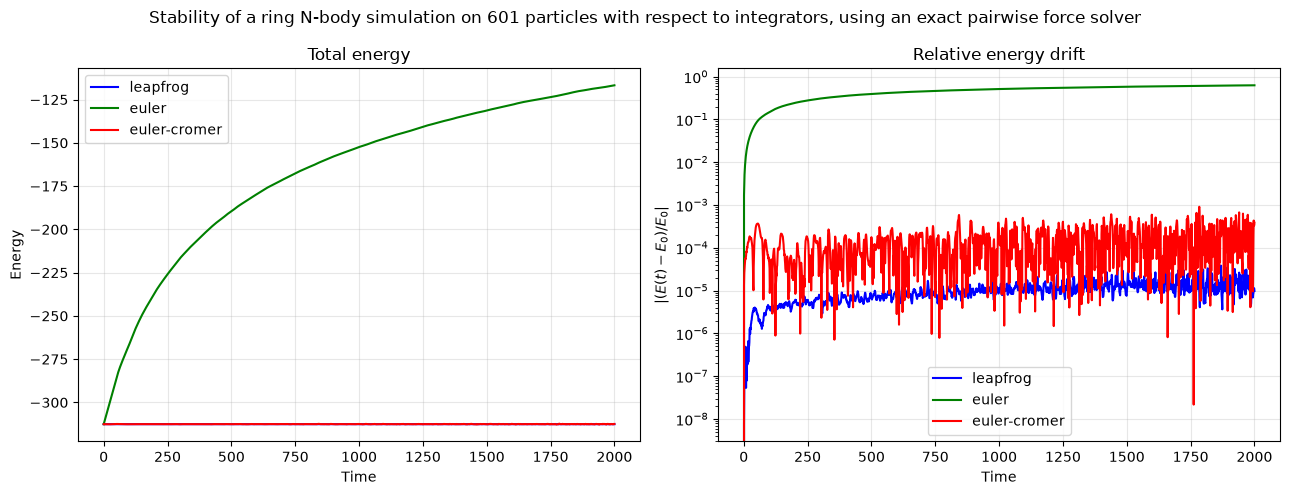

In [ ]:
naive = load_runs('ring_naive')
plot_stability(naive, 'an exact pairwise force solver')

plt.show()